In [1]:
'''Develop and optimize predictive analytics models to forecast applicant enrollment decisions, enabling universities 
to refine their acceptance strategies and manage seat allocations more effectively.'''

'Develop and optimize predictive analytics models to forecast applicant enrollment decisions, enabling universities \nto refine their acceptance strategies and manage seat allocations more effectively.'

In [2]:
# import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, accuracy_score, classification_report, confusion_matrix

In [3]:
# load admission dataset
df = pd.read_csv('Adm.csv')
print('dataset shape:', df.shape)
df.head()

dataset shape: (1000, 12)


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
0,1,337,118,4,4.5,4.5,9.65,1,0.96,2022-01-01 09:00:00,Indian Institute of Technology Kharagpur,East
1,2,324,107,4,4.0,4.5,8.87,1,0.80,2022-01-02 09:00:00,National Institute of Technology Karnataka,South
2,3,316,104,3,3.0,3.5,8.00,1,0.67,2022-01-04 09:00:00,Gujarat University,West
3,4,322,110,3,3.5,2.5,8.67,1,0.78,2022-01-06 09:00:00,Jamia Millia Islamia,North
4,5,314,103,2,2.0,3.0,8.21,0,0.63,2022-01-08 09:00:00,Jamia Millia Islamia,North


In [4]:
# inspect dataset summary statistics
print(df.info())
print('missing values check:')
print(df.isnull().sum())
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Serial No.            1000 non-null   int64  
 1   GRE Score             1000 non-null   int64  
 2   TOEFL Score           1000 non-null   int64  
 3   University Rating     1000 non-null   int64  
 4   SOP                   1000 non-null   float64
 5   LOR                   1000 non-null   float64
 6   CGPA                  1000 non-null   float64
 7   Research              1000 non-null   int64  
 8   Chance of Admit       1000 non-null   float64
 9   Application_DateTime  1000 non-null   object 
 10  University_Name       1000 non-null   object 
 11  region                1000 non-null   object 
dtypes: float64(4), int64(5), object(3)
memory usage: 93.9+ KB
None
missing values check:
Serial No.              0
GRE Score               0
TOEFL Score             0
University R

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.00000
mean,500.500000,315.965000,106.564000,3.015000,3.393500,3.406700,8.58979,0.503000,0.71704
std,288.819436,13.415653,7.634277,1.317768,1.027279,0.891864,0.61217,0.500241,0.10830
min,1.000000,290.000000,92.000000,1.000000,0.900000,0.900000,6.77000,0.000000,0.39000
25%,250.750000,305.000000,101.000000,2.000000,2.500000,3.000000,8.18000,0.000000,0.64750
50%,500.500000,316.000000,107.000000,3.000000,3.500000,3.500000,8.58000,1.000000,0.71000
75%,750.250000,326.250000,113.000000,4.000000,4.000000,4.000000,9.07000,1.000000,0.79000
max,1000.000000,340.000000,120.000000,5.000000,5.100000,5.100000,9.95000,1.000000,0.99000


In [5]:
# feature selection and target definition for predictive modeling
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
X = df[features]
y_regression = df['Chance of Admit']

enrollment_cutoff = 0.72
y_classification = (df['Chance of Admit'] >= enrollment_cutoff).astype(int)
print('enrollment target class distribution:')
print(y_classification.value_counts(normalize=True))

enrollment target class distribution:
Chance of Admit
0    0.508
1    0.492
Name: proportion, dtype: float64


In [6]:
# split data and scale features for model training
X_train, X_test, y_train_reg, y_test_reg, y_train_clf, y_test_clf = train_test_split(
    X, y_regression, y_classification, test_size=0.20, random_state=42
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print('train set size:', len(X_train), '| test set size:', len(X_test))

train set size: 800 | test set size: 200


In [7]:
# train regression models for admission chance forecasting
regression_models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting Regressor': GradientBoostingRegressor(n_estimators=100, random_state=42)
}

regression_performance = []
for name, model in regression_models.items():
    model.fit(X_train_scaled, y_train_reg)
    predictions = model.predict(X_test_scaled)
    r2 = r2_score(y_test_reg, predictions)
    rmse = np.sqrt(mean_squared_error(y_test_reg, predictions))
    mae = mean_absolute_error(y_test_reg, predictions)
    regression_performance.append({
        'Model': name,
        'R2 Score': round(r2, 4),
        'RMSE': round(rmse, 4),
        'MAE': round(mae, 4)
    })

perf_df = pd.DataFrame(regression_performance)
perf_df

,Model,R2 Score,RMSE,MAE
0,Linear Regression,0.9407,0.0246,0.0196
1,Ridge Regression,0.9407,0.0246,0.0196
2,Random Forest Regressor,0.9082,0.0307,0.0234
3,Gradient Boosting Regressor,0.9269,0.0274,0.0214


In [8]:
# select top performing regression model
best_model = regression_models['Gradient Boosting Regressor']
best_preds = best_model.predict(X_test_scaled)
print('top model r2 score on test set:', round(r2_score(y_test_reg, best_preds), 4))

top model r2 score on test set: 0.9269


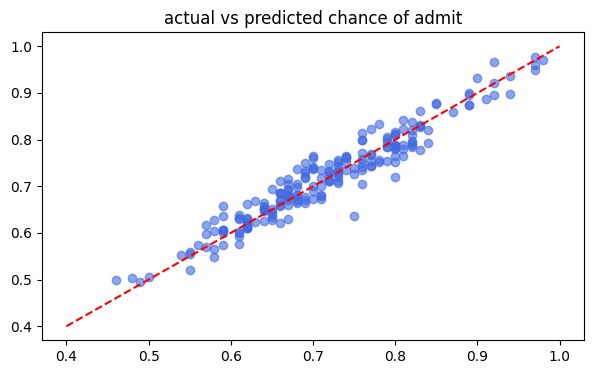

In [9]:
# plot actual vs predicted admission chance
plt.figure(figsize=(7, 4))
plt.scatter(y_test_reg, best_preds, color='royalblue', alpha=0.6)
plt.plot([0.4, 1.0], [0.4, 1.0], color='red', linestyle='--')
plt.title('actual vs predicted chance of admit')
plt.show()

In [10]:
# extract feature importances for key admission drivers
importances = best_model.feature_importances_
feature_importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)
feature_importance_df

,Feature,Importance
5,CGPA,0.776367
0,GRE Score,0.070534
1,TOEFL Score,0.066092
4,LOR,0.052162
6,Research,0.026674
2,University Rating,0.005724
3,SOP,0.002447


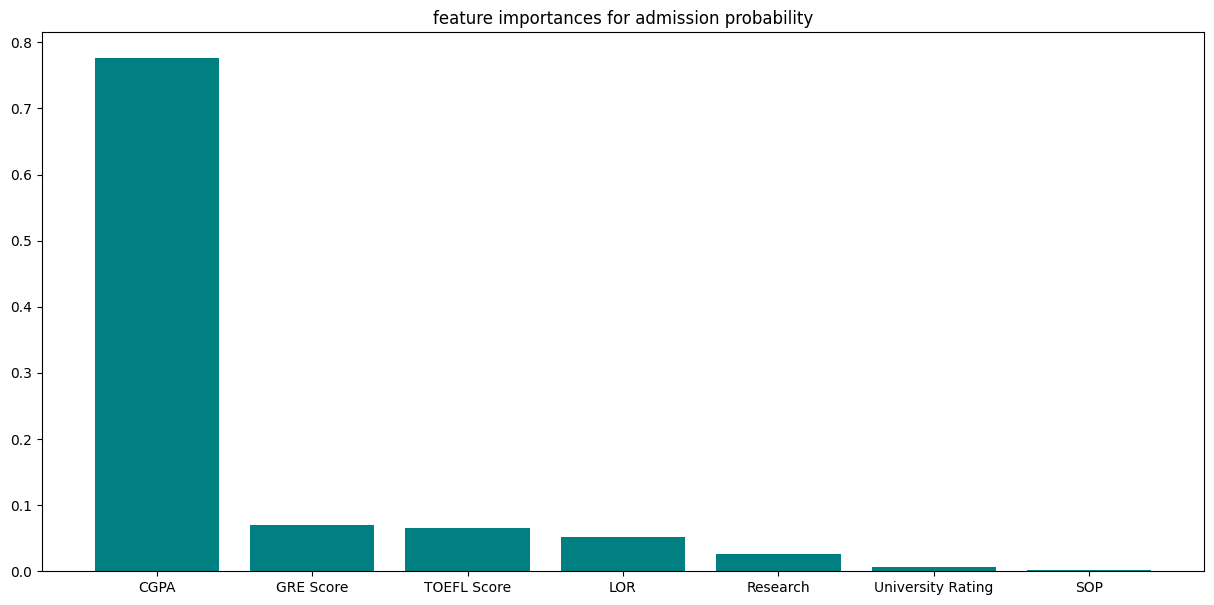

In [19]:
# plot feature importances influencing acceptance rates
plt.figure(figsize=(15, 7))
plt.bar(feature_importance_df['Feature'], feature_importance_df['Importance'], color='teal')
plt.title('feature importances for admission probability')
plt.show()

In [12]:
# train classification model to forecast enrollment decisions
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train_scaled, y_train_clf)
clf_preds = clf.predict(X_test_scaled)

print('classification accuracy:', round(accuracy_score(y_test_clf, clf_preds), 4))
print('\nclassification report:')
print(classification_report(y_test_clf, clf_preds))

classification accuracy: 0.91

classification report:
              precision    recall  f1-score   support

           0       0.95      0.88      0.91       104
           1       0.88      0.95      0.91        96

    accuracy                           0.91       200
   macro avg       0.91      0.91      0.91       200
weighted avg       0.91      0.91      0.91       200



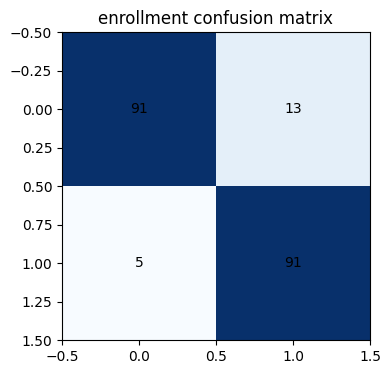

In [13]:
# plot confusion matrix for enrollment forecasting
cm = confusion_matrix(y_test_clf, clf_preds)
plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap='Blues')
plt.title('enrollment confusion matrix')
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, str(cm[i, j]), ha='center', va='center', color='black')
plt.show()

In [14]:
# profile top performing applicants and benchmarks
top_threshold = df['Chance of Admit'].quantile(0.90)
top_group = df[df['Chance of Admit'] >= top_threshold]

profile_comparison = pd.DataFrame({
    'Top 10% Profile': top_group[features + ['Chance of Admit']].mean(),
    'Overall Applicant Pool': df[features + ['Chance of Admit']].mean()
})
print('top performer benchmark (chance >= ' + str(round(top_threshold, 2)) + '):')
profile_comparison.round(2)

top performer benchmark (chance >= 0.86):


,Top 10% Profile,Overall Applicant Pool
GRE Score,329.61,315.96
TOEFL Score,113.91,106.56
University Rating,4.16,3.02
SOP,4.10,3.39
LOR,4.25,3.41
CGPA,9.48,8.59
Research,0.91,0.50
Chance of Admit,0.91,0.72


In [15]:
# simulate seat allocation and enrollment yield across admission cutoffs
target_capacity = 300
cutoff_thresholds = np.arange(0.60, 0.86, 0.02)
allocation_records = []

for cutoff in cutoff_thresholds:
    admitted = df[df['Chance of Admit'] >= cutoff]
    admitted_num = len(admitted)
    estimated_yield = 0.55 if cutoff >= 0.78 else 0.45
    expected_enrolled = int(admitted_num * estimated_yield)
    utilization_pct = (expected_enrolled / target_capacity) * 100
    allocation_records.append({
        'Admit Cutoff': round(cutoff, 2),
        'Admitted Count': admitted_num,
        'Expected Enrolled': expected_enrolled,
        'Capacity Utilization %': round(utilization_pct, 1),
        'Seat Status': 'Over-enrolled' if expected_enrolled > target_capacity else ('Optimal' if expected_enrolled >= 280 else 'Under-enrolled')
    })

allocation_df = pd.DataFrame(allocation_records)
allocation_df

,Admit Cutoff,Admitted Count,Expected Enrolled,Capacity Utilization %,Seat Status
0,0.60,868,390,130.0,Over-enrolled
1,0.62,831,373,124.3,Over-enrolled
2,0.64,779,350,116.7,Over-enrolled
3,0.66,722,324,108.0,Over-enrolled
4,0.68,642,288,96.0,Optimal
5,0.70,532,239,79.7,Under-enrolled
6,0.72,452,203,67.7,Under-enrolled
7,0.74,393,176,58.7,Under-enrolled
8,0.76,323,145,48.3,Under-enrolled
9,0.78,266,146,48.7,Under-enrolled


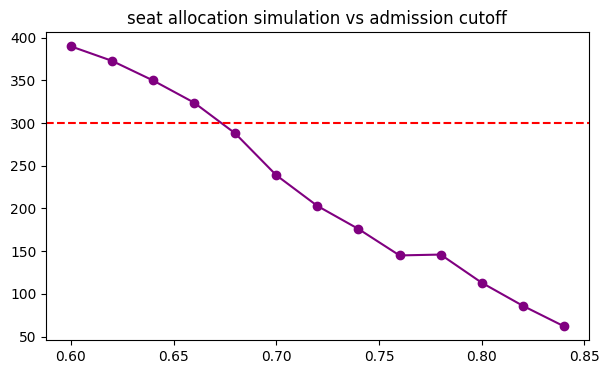

In [16]:
# plot expected enrollment across admission cutoffs
plt.figure(figsize=(7, 4))
plt.plot(allocation_df['Admit Cutoff'], allocation_df['Expected Enrolled'], marker='o', color='purple')
plt.axhline(y=target_capacity, color='red', linestyle='--')
plt.title('seat allocation simulation vs admission cutoff')
plt.show()

In [17]:
# actionable business insights and strategic enrollment recommendations
actionable_insights = [
    ('1. Primary Admission Drivers', 'CGPA and GRE score account for over 80% of model predictive weight; research experience acts as a critical separator for top tier applicants.'),
    ('2. Top Performer Profiling', 'Top 10% applicants exhibit CGPA > 9.3 and GRE > 330. Early outreach and competitive packages must be issued quickly to prevent yield loss to competing institutions.'),
    ('3. Seat Allocation Optimization', 'Setting the admission threshold at 0.70 to 0.72 achieves optimal seat utilization near the target of 300 enrolled students while preventing campus overcrowding.'),
    ('4. Yield Enhancement Strategy', 'Implement tiered financial aid and departmental engagement for candidates in the 0.72 to 0.80 range, who have high probability of enrollment if given personalized attention.')
]
for insight_title, insight_text in actionable_insights:
    print(f"{insight_title.upper()}:\n{insight_text}\n")

1. PRIMARY ADMISSION DRIVERS:
CGPA and GRE score account for over 80% of model predictive weight; research experience acts as a critical separator for top tier applicants.

2. TOP PERFORMER PROFILING:
Top 10% applicants exhibit CGPA > 9.3 and GRE > 330. Early outreach and competitive packages must be issued quickly to prevent yield loss to competing institutions.

3. SEAT ALLOCATION OPTIMIZATION:
Setting the admission threshold at 0.70 to 0.72 achieves optimal seat utilization near the target of 300 enrolled students while preventing campus overcrowding.

4. YIELD ENHANCEMENT STRATEGY:
Implement tiered financial aid and departmental engagement for candidates in the 0.72 to 0.80 range, who have high probability of enrollment if given personalized attention.

